# Continuous Bayesian optimization

Suppose evaluating a function requires an expensive experiment. Where should we
run the next one if we want to find its minimum?

We'll start with three observations on $[-2.5, 2.5]$, fit a GP posterior, and use
expected improvement to choose the next location. gpex handles the posterior;
we'll write the acquisition and optimization loop below.

## Start with three observations

Our example objective is cheap enough to plot, but we'll only give the GP the
values at the locations we select. A small observation variance keeps the
covariance system well conditioned.

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

jax.config.update("jax_enable_x64", True)
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.5),
        "figure.dpi": 120,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.18,
        "font.size": 10,
        "axes.prop_cycle": plt.cycler(color=["#1F4E79", "#D97706", "#6D597A"]),
    }
)
BLUE, ORANGE, PURPLE = "#1F4E79", "#D97706", "#6D597A"


def band(ax, x, prediction, name, label="Posterior", color=BLUE):
    mean = np.asarray(prediction.mean[name]).reshape(-1)
    sd = np.sqrt(
        np.maximum(np.asarray(prediction.covariance.variance[name]), 0)
    ).reshape(-1)
    ax.plot(x, mean, color=color, label=label)
    ax.fill_between(x, mean - 1.96 * sd, mean + 1.96 * sd, color=color, alpha=0.15)

In [2]:
import jax
import optax
from jax.scipy.special import ndtr

from gpex import (
    FunctionalBlock,
    FunctionalDataset,
    FunctionalQuery,
    GaussianProcess,
    ObservationBlock,
    ObservationDesignBlock,
)
from gpex.blocks import Locations
from gpex.kernels import RBFKernel
from gpex.operators import Identity


def objective(x):
    return 0.15 * x**2 + jnp.sin(2.3 * x)


lower = jnp.array([-2.5])
upper = jnp.array([2.5])
observation_variance = 1e-5
x_observed = jnp.array([[-2.0], [0.0], [2.0]])
y_observed = objective(x_observed[:, 0])

measured_values = FunctionalBlock(Locations(x_observed), Identity(), "objective")
initial_design = ObservationDesignBlock(
    measured_values, variance=observation_variance, max_size=7
)
dataset = FunctionalDataset([ObservationBlock(initial_design, y=y_observed)])
gp = GaussianProcess(RBFKernel(variance=1.0, lengthscale=0.7))
posterior = gp.condition(dataset)

## Expected improvement

At a proposed location, the GP gives us a distribution over the function value.
Expected improvement asks how much lower that value might be than the best one
we've observed, averaged over this distribution. It can favor a location with a
low predicted mean or one where uncertainty leaves room for improvement.

In [3]:
def expected_improvement(posterior, point, best_value):
    query = FunctionalQuery(
        [FunctionalBlock(Locations(point[None, :]), Identity(), "objective")]
    )
    prediction = posterior.predict(query)
    mean = prediction.mean["objective"][0]
    variance = prediction.covariance.variance["objective"][0]
    standard_deviation = jnp.sqrt(jnp.maximum(variance, 1e-12))

    improvement = best_value - mean
    standardized = improvement / standard_deviation
    density = jnp.exp(-0.5 * standardized**2) / jnp.sqrt(2.0 * jnp.pi)
    return improvement * ndtr(standardized) + standard_deviation * density

## Optimize the acquisition

Expected improvement can have several peaks. We'll run a gradient-based
optimizer from twelve starting points, then keep the best result.

A sigmoid keeps each proposed location within the bounds.
`jax.value_and_grad` differentiates through the posterior and the acquisition,
so the optimizer can move continuously through the domain.

In [4]:
optimizer = optax.adam(learning_rate=0.06)


def in_domain(unconstrained):
    return lower + (upper - lower) * jax.nn.sigmoid(unconstrained)


def optimize_one_start(initial, posterior, best_value):
    state = optimizer.init(initial)

    def step(carry, _):
        unconstrained, state = carry

        def loss(parameters):
            point = in_domain(parameters)
            return -expected_improvement(posterior, point, best_value)

        value, gradient = jax.value_and_grad(loss)(unconstrained)
        updates, state = optimizer.update(gradient, state, unconstrained)
        unconstrained = optax.apply_updates(unconstrained, updates)
        return (unconstrained, state), value

    (unconstrained, _), _ = jax.lax.scan(step, (initial, state), xs=None, length=100)
    point = in_domain(unconstrained)
    value = expected_improvement(posterior, point, best_value)
    return point, value


def optimize_acquisition(key, posterior, best_value, start_count=12):
    starts = jax.random.normal(key, (start_count, lower.size))
    points, values = jax.vmap(
        lambda start: optimize_one_start(start, posterior, best_value)
    )(starts)
    best_start = jnp.argmax(values)
    return points[best_start], points

The `argmax` above chooses among the optimized locations. Those locations came
from continuous optimization, rather than a candidate grid.

## Take a reading and repeat

We evaluate the objective at the selected location and append the reading to
the posterior. The next iteration then uses everything we've observed so far.

In [5]:
@jax.jit
def append_observation(posterior, x, y):
    return posterior.append(Locations(x), y, block="objective")


key = jax.random.key(7)

initial_posterior = posterior
first_point = None
first_restart_points = None

for iteration in range(4):
    key, acquisition_key = jax.random.split(key)
    next_point, restart_points = optimize_acquisition(
        acquisition_key,
        posterior,
        best_value=jnp.min(y_observed),
    )
    x_next = next_point[None, :]
    if iteration == 0:
        first_point = next_point
        first_restart_points = restart_points
    y_next = objective(x_next[:, 0])
    posterior = append_observation(posterior, x_next, y_next)
    x_observed = jnp.concatenate((x_observed, x_next))
    y_observed = jnp.concatenate((y_observed, y_next))

best_index = jnp.argmin(y_observed)
print("best x:", x_observed[best_index, 0])
print("best value:", y_observed[best_index])

best x: -0.6383955983724534
best value: -0.9336205179047086


In an application, `objective(x_next)` would call your experiment or simulator.
Here we keep the hyperparameters fixed across iterations. If you refit them,
rebuild the posterior from all observations before choosing the next location.

Let's look back at the first decision. The grid below is only for drawing the
posterior and acquisition curves.

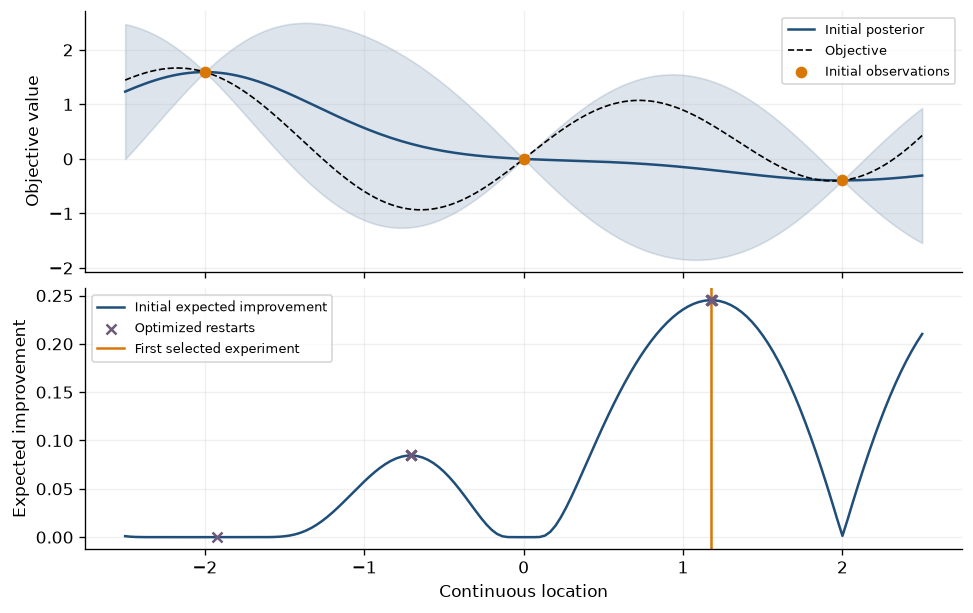

In [6]:
# A grid is used only to draw the curves, never to choose an experiment.
x_plot = jnp.linspace(-2.5, 2.5, 151)
query = FunctionalQuery(
    [FunctionalBlock(Locations(x_plot[:, None]), Identity(), "objective")]
)
initial_prediction = initial_posterior.predict(query)
initial_best = jnp.min(y_observed[:3])
ei_curve = jax.vmap(
    lambda t: expected_improvement(initial_posterior, t[None], initial_best)
)(x_plot)
restart_ei = jax.vmap(
    lambda t: expected_improvement(initial_posterior, t, initial_best)
)(first_restart_points)
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True, layout="constrained")
band(axes[0], x_plot, initial_prediction, "objective", "Initial posterior")
axes[0].plot(x_plot, objective(x_plot), "k--", lw=1, label="Objective")
axes[0].scatter(
    x_observed[:3, 0],
    y_observed[:3],
    color=ORANGE,
    label="Initial observations",
    zorder=3,
)
axes[0].set(ylabel="Objective value")
axes[1].plot(x_plot, ei_curve, label="Initial expected improvement")
axes[1].scatter(
    first_restart_points[:, 0],
    restart_ei,
    color=PURPLE,
    marker="x",
    label="Optimized restarts",
    zorder=4,
)
axes[1].axvline(float(first_point[0]), color=ORANGE, label="First selected experiment")
axes[1].set(xlabel="Continuous location", ylabel="Expected improvement")
for ax in axes:
    ax.legend(fontsize=8)
plt.show()
assert np.all(np.asarray(x_observed) >= -2.5) and np.all(np.asarray(x_observed) <= 2.5)
assert np.isfinite(restart_ei).all()
assert np.isfinite(
    jax.grad(lambda t: expected_improvement(initial_posterior, t, initial_best))(
        jnp.array([0.3])
    )
).all()

The crosses mark the locations reached by the twelve optimization runs. Some
runs found a smaller acquisition peak; the orange line marks the best result.
Multiple starts help explore those alternatives, although they don't guarantee
a global optimum.